# Caribu, 5: experimental data

**What you will learn:** give the model a measured weather (the PAR above the canopy, hour by hour), compare its
output with light measured under the canopy, measure the difference, and fit a parameter so that the model matches
the measurements.

**You need:** tutorials 1 and 2, and a little pandas. **Run time:** about 30 seconds.

**About the data.** The files in `data/` are **synthetic**: `data/make_synthetic_data.py` made them from the model
itself, with a known leaf width and some random noise. They stand for what an experiment gives. Since the true value
is known, we can check that the fit finds it. Your own measurements go in files of the same form.

## 1. The data

- `weather_PAR.csv`: the PAR above the canopy (µmol m⁻² s⁻¹), hour by hour (universal time), on a partly cloudy
  21 June, as a weather station's PAR sensor would give;
- `observed_soil_PAR.csv`: the PAR reaching the soil under the stand, from 8 to 16 h, as a line of light sensors
  laid on the ground between the rows would measure it.

They are read with pandas:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.caribu.simulation import simulate

weather = pd.read_csv("data/weather_PAR.csv")
observed = pd.read_csv("data/observed_soil_PAR.csv")
observed

,hour,soil_PAR
0,8.0,107.6
1,9.0,198.3
2,10.0,184.0
3,11.0,100.4
4,12.0,190.7
5,13.0,108.8
6,14.0,146.0
7,15.0,98.1
8,16.0,110.6


## 2. A measured input: the weather

`simulate` takes the PAR above the canopy as `PARi`: a number, a function of the hour, or a pandas Series indexed by
hour (interpolated between the hours). With the sun on, the share of diffuse light is estimated from it: the darker
the hour, the cloudier, the more diffuse.

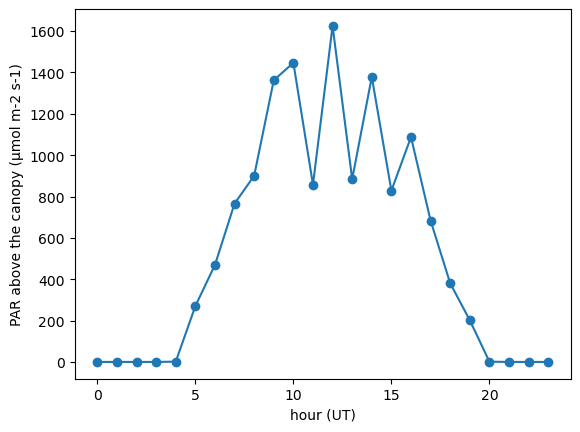

In [2]:
PARi = weather.set_index("hour")["PARi"]
plt.plot(PARi.index, PARi.values, marker="o")
plt.xlabel("hour (UT)"); plt.ylabel("PAR above the canopy (µmol m-2 s-1)");

In [3]:
default = simulate({"sun": True}, hours=9, start_hour=8, PARi=PARi)

## 3. Compare with the observations

The model's PAR reaching the soil is the PAR above the canopy times `soil_fraction`. The simulated values and the
observed points on the same axes:

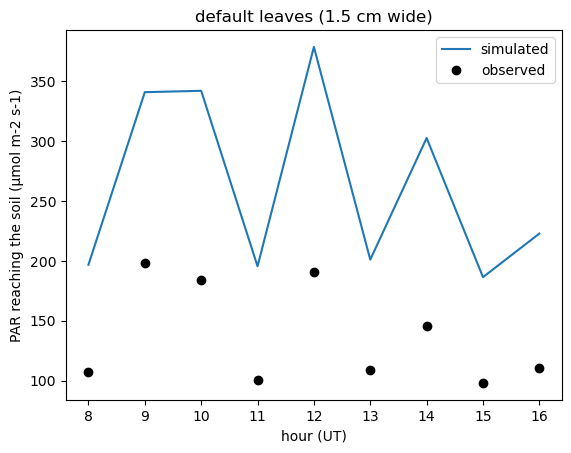

In [4]:
def soil_PAR(result):
    return result.summary["PARi"] * result.summary["soil_fraction"]


def compare(result, title):
    plt.plot(result.summary["hour"], soil_PAR(result), label="simulated")
    plt.plot(observed["hour"], observed["soil_PAR"], "o", color="k", label="observed")
    plt.xlabel("hour (UT)"); plt.ylabel("PAR reaching the soil (µmol m-2 s-1)"); plt.title(title); plt.legend()


compare(default, "default leaves (1.5 cm wide)")

Too much light reaches the soil in the model: the real canopy has more leaf area. A single number measures the
difference: the **root mean square error** (RMSE) between the simulated and observed values, here relative to the
observed values so that it reads as a percentage.

In [5]:
def relative_rmse(result):
    return float(np.sqrt(np.mean(((soil_PAR(result).values - observed["soil_PAR"].values)
                                  / observed["soil_PAR"].values) ** 2)))


print(f"{100 * relative_rmse(default):.0f} % of error with the default leaves")

91 % of error with the default leaves


## 4. Fit a parameter

The plants' size was not measured; their leaf width is uncertain. Fitting it means finding the width that makes the
error smallest. `scipy.optimize.minimize_scalar` searches it between two bounds by running the model repeatedly:

In [6]:
from scipy.optimize import minimize_scalar


def error(leaf_width):
    return relative_rmse(simulate({"sun": True, "leaf_width": leaf_width}, hours=9, start_hour=8, PARi=PARi))


fit = minimize_scalar(error, bounds=(0.008, 0.04), method="bounded", options={"xatol": 1e-4})
print(f"fitted leaf width = {100 * fit.x:.2f} cm after {fit.nfev} simulations; error {100 * fit.fun:.1f} %")
print("the value used to make the synthetic data: 2.2 cm")

fitted leaf width = 2.22 cm after 9 simulations; error 2.9 %
the value used to make the synthetic data: 2.2 cm


the stand's LAI with the fitted leaves: 2.36


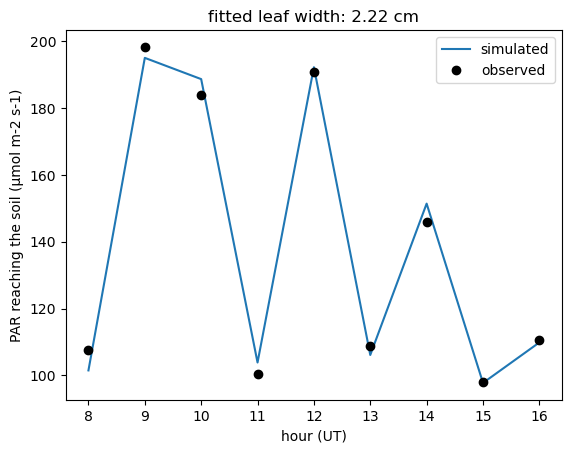

In [7]:
fitted = simulate({"sun": True, "leaf_width": fit.x}, hours=9, start_hour=8, PARi=PARi)
compare(fitted, f"fitted leaf width: {100 * fit.x:.2f} cm")
LAI = fitted.plants()["leaf_area"].sum() / fitted.ground_area
print(f"the stand's LAI with the fitted leaves: {LAI:.2f}")

The fitted width is close to the true one; what is left of the error is the noise added to the data. Through the
leaf width, the fit estimates the canopy's **leaf area index** from light measured under it, as experimenters do
with light sensors in the field (tutorial 3's Beer's law is the simplest form of this).

**A caution.** The model's `soil_fraction` counts the light that reaches the soil through the gaps, without touching
a leaf (the direct model). A real sensor under the canopy also receives the light transmitted through the leaves, and
scattered. With real data, use the nested model (`"mode": "nested"`), whose soil light includes it, or measure in
the gaps. Fitting on real data, keep part of the observations to check the fitted model on them.

## 5. What the canopy absorbed

With the fitted leaves, the PAR the stand absorbed over the measured hours:

In [8]:
summary = fitted.summary
print(f"8-16 h: {summary['PARi'].sum() * 3600 / 1e6:.1f} mol m-2 above the canopy, "
      f"{summary['PAR_absorbed'].sum() * 3600 / 1e6:.1f} mol m-2 absorbed")

8-16 h: 37.3 mol m-2 above the canopy, 28.0 mol m-2 absorbed


## Try it yourself

1. Fit the leaf inclination instead of the width (between 0 and 85°). Does it fit as well? Why can two different
   parameters explain the same measurements?
2. Fit the width again with the overcast sky (no sun). Is the fitted value the same? Which assumption is right
   depends on the day's weather.
3. Prepare a CSV of your own weather (columns `hour` and `PARi`) and light the stand with it.

**Next:** `06_with_other_models.ipynb`.